# Beer Game: token constraints, information sharing and bullwhip

**Start here. This notebook implements the new `ThoughtsReflection_Paragraph.docx`, not the earlier training experiment.**

1. **H1:** short preparation budgets reduce the fitted weight on outstanding replenishment (beta).
2. **H2:** short preparation budgets increase team holding/backlog cost.
3. Both conditions share all four roles' current inventories. There is **no trained/control condition**.
4. The same GPT-5.4 nano snapshot uses `reasoning.effort="none"` in both conditions. The API enforces different **visible memo-token caps**, followed by an identical **192-token structured final answer**. This is an operational proxy for constrained preparation, not a measure of human seconds or total internal cognition.
5. **Default: free offline calibration.** No API key or payment is needed. API calibration comes before a small game pilot; no automatic large study.

The source document is [here](../data/source/ThoughtsReflection_Paragraph.docx). Full protocol: [docs/PROTOCOL.md](../docs/PROTOCOL.md).

## 1. Setup (once)

Use a Python 3.9+ Jupyter kernel. If imports fail, run the commented installation line below, then restart the kernel. Never paste an API key into notebook source or outputs.

In [1]:
from pathlib import Path
import sys, os, getpass, importlib
from IPython.display import display, Markdown, Image
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for parent in candidates for p in
    (parent, parent / "beer_game_experiment", parent / "Project" / "beer_game_experiment")
    if (p / "src" / "beergame_study").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the beer_game_experiment project.")
# If needed, uncomment this line, run it, then restart the kernel:
# %pip install -r {ROOT / "requirements.txt"}
sys.path.insert(0, str(ROOT / "src"))
from beergame_study import Config, run, run_directory, report, software_checks
from beergame_study.api import StudyStopped
print("Project:", ROOT)

Project: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment


## 2. Settings and cost

- `MODE="offline"`: deterministic software check, **not GPT evidence**. The same synthetic rule operates in both conditions.
- `MODE="api"`, `STAGE="calibration"`: 24 independent hypothetical states × reference/short/adequate/doubled allowance × two stages = **192 planned calls**. P25/P95 of reference memo use suggest candidate caps; the screen checks truncation and benchmark differences. This economical screen differs from the reflection's four-chain human calibration.
- After a **passed API calibration**, set `STAGE="game"`, copy its suggested caps and folder into the settings. Start with `GROUPS_PER_CONDITION=1` (two chains, eight agents). Use **2 for a four-chain, 16-agent pilot**. The reflection's main design uses **10 per condition = 20 chains = 80 agents**; do not automatically scale.
- Game: 40 weeks, first four fixed-order warmup weeks, then 36 decision weeks. Another 12 weeks are scored automatically, with no API calls.
- Rates checked 2026-10-04: $0.20 input / $0.02 cached input / $1.25 output per million tokens. [Official model documentation](https://developers.openai.com/api/docs/models/gpt-5.4-nano). Cost estimates below assume 1,500 input tokens/call; actual cost varies with history and output. The local allowance is a guard, not your account balance.

**Resume:** keep experiment settings and replicate ID fixed; raise only the dollar allowance if required. Scientific/code changes create a new folder. No earlier experiment data are reused.

In [2]:
MODE = "offline"                # Change to "api" only when ready to spend
STAGE = "game"           # "calibration" first, then "game"
GROUPS_PER_CONDITION = 1         # 1=8 agents, 2=16 agents, 10=80 agents (two conditions)
SHORT_TOKENS = 64               # Provisional; replace with API calibration result
ADEQUATE_TOKENS = 256           # Provisional; replace with API calibration result
CALIBRATION_RUN = ""            # Paste passed API calibration folder for STAGE="game"
COLLECT_DEBRIEFS = False         # Optional post-game questionnaire; +1 call per agent
BUDGET_USD = 1.05               # Total allowance for THIS run, including cached spending
REPLICATE_ID = "token-pilot-01"
CONFIG = Config(mode=MODE, stage=STAGE, replicate_id=REPLICATE_ID,
    groups_per_condition=GROUPS_PER_CONDITION, short_tokens=SHORT_TOKENS,
    adequate_tokens=ADEQUATE_TOKENS, calibration_run=CALIBRATION_RUN,
    budget_usd=BUDGET_USD, collect_debriefs=COLLECT_DEBRIEFS)
CONFIG.validate()
run_dir = run_directory(ROOT, CONFIG)
planned = 192 if STAGE == "calibration" else 8 * GROUPS_PER_CONDITION * (1 + 2 * 36 + int(COLLECT_DEBRIEFS))
output_allowance = (24 * (1024 + SHORT_TOKENS + ADEQUATE_TOKENS + 2*ADEQUATE_TOKENS + 4*192)
                    if STAGE == "calibration" else
                    GROUPS_PER_CONDITION * (4*36*(SHORT_TOKENS+ADEQUATE_TOKENS+2*192) + 8*192 + 8*384*int(COLLECT_DEBRIEFS)))
scenario = (planned*1500*.20 + output_allowance*1.25)/1e6
print(f"{MODE} / {STAGE}; {planned} planned calls plus transport retries/replacements")
print(f"Illustrative cost at 1,500 input tokens/call and full output use: ${scenario:.2f}; not a quote.")
print(f"Request pacing alone: at least {planned * CONFIG.request_interval_s / 60:.1f} minutes for an uncached run.")
print("Local allowance:", BUDGET_USD, "USD; result folder:", run_dir)

offline / game; 584 planned calls plus transport retries/replacements
Illustrative cost at 1,500 input tokens/call and full output use: $0.30; not a quote.
Request pacing alone: at least 9.7 minutes for an uncached run.
Local allowance: 1.05 USD; result folder: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/data/runs/game_offline_b2af000ddb619fcc


## 3. Free checks before any paid call

Checks include simulator conservation, final-order consequences, beta recovery with legitimate zero orders, and a sensible benchmark outperforming always-zero/always-large ordering. They verify the software, not GPT behavior.

In [3]:
checks = software_checks()
display(checks)
assert checks.passed.all()
print("Free checks passed. No API calls made by this cell.")

,check,passed,detail
0,Simple demand benchmark beats always-zero and ...,True,"{'zero': 9368.0, 'demand': 156.0, 'large': 262..."
1,Final order affects score: retailer,True,"[116.0, 0.0, 592.0]"
2,Final order affects score: wholesaler,True,"[168.0, 0.0, 352.0]"
3,Final order affects score: distributor,True,"[204.0, 0.0, 208.0]"
4,Final order affects score: factory,True,"[224.0, 0.0, 160.0]"
5,"Known beta recovery, including valid zero orders",True,0.65
6,Bullwhip ratio undefined for constant denominator,True,"NaN, not infinity or zero"


Free checks passed. No API calls made by this cell.


## 4. Run the selected stage

This is the only paid cell in API mode. It requests the key in a hidden prompt. Progress shows completed/remaining calls, cached calls, active requests and spending.

A preparation memo reaching its cap is **not a comprehension failure**: the same final-answer allowance follows. Final answers must have a valid nonnegative integer and correct state readbacks. Temporary service errors get bounded retries with pacing/cooldown. A failed final answer may replace the entire four-role group once; failed groups stay recorded and inferential p-values are withheld after replacement. There is no retry-until-good strategy and no automatic model/budget upgrade.

In [4]:
client = None
try:
    if MODE == "api":
        from openai import AsyncOpenAI
        key = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OpenAI API key (hidden): ")
        if not key.strip():
            raise ValueError("No API key entered.")
        client = AsyncOpenAI(api_key=key.strip(), max_retries=0, timeout=CONFIG.timeout_s)
        del key
    run_dir = await run(ROOT, CONFIG, client=client)
    print("Stage complete. Read the report below before proceeding.")
except StudyStopped as exc:
    print("Stopped:", str(exc))
    print("Saved folder:", run_dir)
finally:
    if client is not None:
        await client.close()

Stage complete. Read the report below before proceeding.


## 5. Conclusions and full results

The report leads with conclusions. It saves Word, Markdown, Excel, CSV and plots inside the displayed run folder.

- **H1:** group beta from four identified role estimates; report missing/unreliable fits rather than forcing a value.
- **H2:** total team cost, analyzed independently of beta availability. No p-values from the tiny pilot or synthetic data.
- **Bullwhip (牛鞭效应):** order variance divided by incoming-demand variance at each role, plus order variance divided by external-customer-demand variance for comparison along the chain. Above 1 means amplification relative to that denominator. Also inspect the time series, backlog and inventory. Constant denominators produce missing ratios, not invented zeros.
- The warmup and demand step are retained in the variance window; after the step alone, customer demand is constant. Ratios from this transient experiment are descriptive, not stationary demand estimates.
- Zero orders may follow excess ordering/stock. There is **no advertised order maximum** and no reward for matching a cap. An undisclosed numerical safety check halts absurd-scale orders above 100,000 without clipping them.

[MIT rules and delay dynamics](https://web.mit.edu/jsterman/www/SDG/beergame.html) · [Original bullwhip research](https://pubsonline.informs.org/doi/10.1287/mnsc.43.4.546)

# Token-budget Beer Game — conclusions

1. SYNTHETIC SOFTWARE CHECK: no GPT evidence or hypothesis inference.
2. Run status: complete. Estimated cost/reservations: $0.0000.
3. Saved successful API stages: 584; other saved attempts: 0.
4. Completed groups: 2/2; usable beta: 8/8 roles.
5. H1 tests lower beta under the short allowance; H2 tests higher total scored cost. H2 does not require usable beta. See the separate status for each test.
6. Review token separation, failures, cost and bullwhip plots before increasing sample size. Zero orders and large orders are outcomes, not automatic grounds for discarding a group.
Cost is holding plus backlog, including warmup and the 12 automatic terminal weeks. Automatic decisions never enter beta, token-use or bullwhip estimates. Fulfillment counts late delivery; it is not an on-time service rate. Bullwhip ratios use all game weeks including warmup because retailer demand is constant after the step; a constant denominator is reported as missing. The deterministic demand step limits generalization.
Beta is a structural-model diagnostic, not profit. No artificial upper order cap is fitted. Rank, response strength, variation and positive-order checks flag unreliable fits. A sample of at least eight paired chains is a computational inference floor, not a power calculation. The reflection proposes ten chains per condition; no sample size guarantees significance.

![Order trajectories](order_trajectories.png)
![Bullwhip by role](bullwhip.png)

## Group outcomes

```
     group_id  block condition  agent_phase_cost  continuation_cost  total_scored_cost  group_beta  usable_role_betas  customer_fulfillment  retailer_backlog_weeks  terminal_inventory  terminal_backlog
b000_adequate      0  adequate            1220.0              336.0             1556.0      0.6509                  4                   1.0                       0                  56                 0
   b000_short      0     short            1220.0              336.0             1556.0      0.6509                  4                   1.0                       0                  56                 0
```

## Token manipulation

```
condition  mean_preparation_tokens  median_preparation_tokens  truncated_fraction  mean_final_tokens  zero_rate  max_order
 adequate                      0.0                        0.0                 0.0                0.0     0.0278         31
    short                      0.0                        0.0                 0.0                0.0     0.0278         31
```

## Hypothesis tests

```
hypothesis           outcome  estimate  complete_pairs      predicted_direction  p_raw                                                                                    status  p_holm
        H1        group_beta       0.0               1 short minus adequate < 0    NaN withheld: offline, fewer than 8 pairs, incomplete sample, replacement, or missing outcome     NaN
        H2 total_scored_cost       0.0               1 short minus adequate > 0    NaN withheld: offline, fewer than 8 pairs, incomplete sample, replacement, or missing outcome     NaN
```

## Role performance and bullwhip

```
     group_id        role condition  holding_cost  backlog_cost  bullwhip_vs_local  bullwhip_vs_customer  order_variance  mean_order  zero_rate  max_order  backlog_weeks  max_backlog  terminal_backlog
b000_adequate distributor  adequate         256.0          95.0             2.4505               14.7530         21.7891      8.9167     0.0000         23              6           22                 0
b000_adequate     factory  adequate         286.0          84.0             2.0792               31.3611         46.3179      9.2222     0.1111         31              5           31                 0
b000_adequate    retailer  adequate         234.0           0.0             1.9080                1.9080          2.8179      8.3889     0.0000         12              0            0                 0
b000_adequate  wholesaler  adequate         223.0          42.0             2.6361                5.7253          8.4558      8.6389     0.0000         17              8            8                 0
   b000_short distributor     short         256.0          95.0             2.4505               14.7530         21.7891      8.9167     0.0000         23              6           22                 0
   b000_short     factory     short         286.0          84.0             2.0792               31.3611         46.3179      9.2222     0.1111         31              5           31                 0
   b000_short    retailer     short         234.0           0.0             1.9080                1.9080          2.8179      8.3889     0.0000         12              0            0                 0
   b000_short  wholesaler     short         223.0          42.0             2.6361                5.7253          8.4558      8.6389     0.0000         17              8            8                 0
```

## Beta diagnostics

```
     group_id        role condition  block  positive_orders  theta  alpha   beta  target   rmse     r2  jac_condition  usable fit_flag  n order_limit  cap_hit_rate
b000_adequate distributor  adequate      0               36    1.0 0.3459 0.6620 24.5036 0.1889 0.9983         4.3806    True       ok 36        None           0.0
b000_adequate     factory  adequate      0               32    1.0 0.3387 0.6411 24.5202 0.2974 0.9981         5.2894    True       ok 36        None           0.0
b000_adequate    retailer  adequate      0               36    1.0 0.3385 0.6912 24.9892 0.1976 0.9653        12.3089    True       ok 36        None           0.0
b000_adequate  wholesaler  adequate      0               36    1.0 0.3476 0.6095 22.8634 0.2230 0.9929         5.3218    True       ok 36        None           0.0
   b000_short distributor     short      0               36    1.0 0.3459 0.6620 24.5036 0.1889 0.9983         4.3806    True       ok 36        None           0.0
   b000_short     factory     short      0               32    1.0 0.3387 0.6411 24.5202 0.2974 0.9981         5.2894    True       ok 36        None           0.0
   b000_short    retailer     short      0               36    1.0 0.3385 0.6912 24.9892 0.1976 0.9653        12.3089    True       ok 36        None           0.0
   b000_short  wholesaler     short      0               36    1.0 0.3476 0.6095 22.8634 0.2230 0.9929         5.3218    True       ok 36        None           0.0
```

## Interpretation limits

This protocol restricts visible preparation tokens plus a common final-response allowance, with reasoning effort none. It does not directly limit hidden cognitive effort, wall-clock time or human thinking time. Prompts cannot reliably count remaining tokens; the API hard cap is the enforced constraint. A truncated memo is accepted as a deadline outcome, then a common 192-token stage solicits the order. The final stage can still involve implicit computation, and unused token allowance is not effort used.
Technical retries retain the same prompt and cap. Failed final responses can replace a whole group only within the configured limit; all failed attempts remain recorded. Replacement selection withholds inferential p-values. No order is clipped or replaced by a fabricated answer. The separate emergency scale check stops the run rather than making a boundary order.

Sources: [provided reflection](../../source/ThoughtsReflection_Paragraph.docx); [MIT Beer Game](https://web.mit.edu/jsterman/www/SDG/beergame.html); [Lee, Padmanabhan & Whang](https://pubsonline.informs.org/doi/10.1287/mnsc.43.4.546); [OpenAI model documentation](https://developers.openai.com/api/docs/models/gpt-5.4-nano).


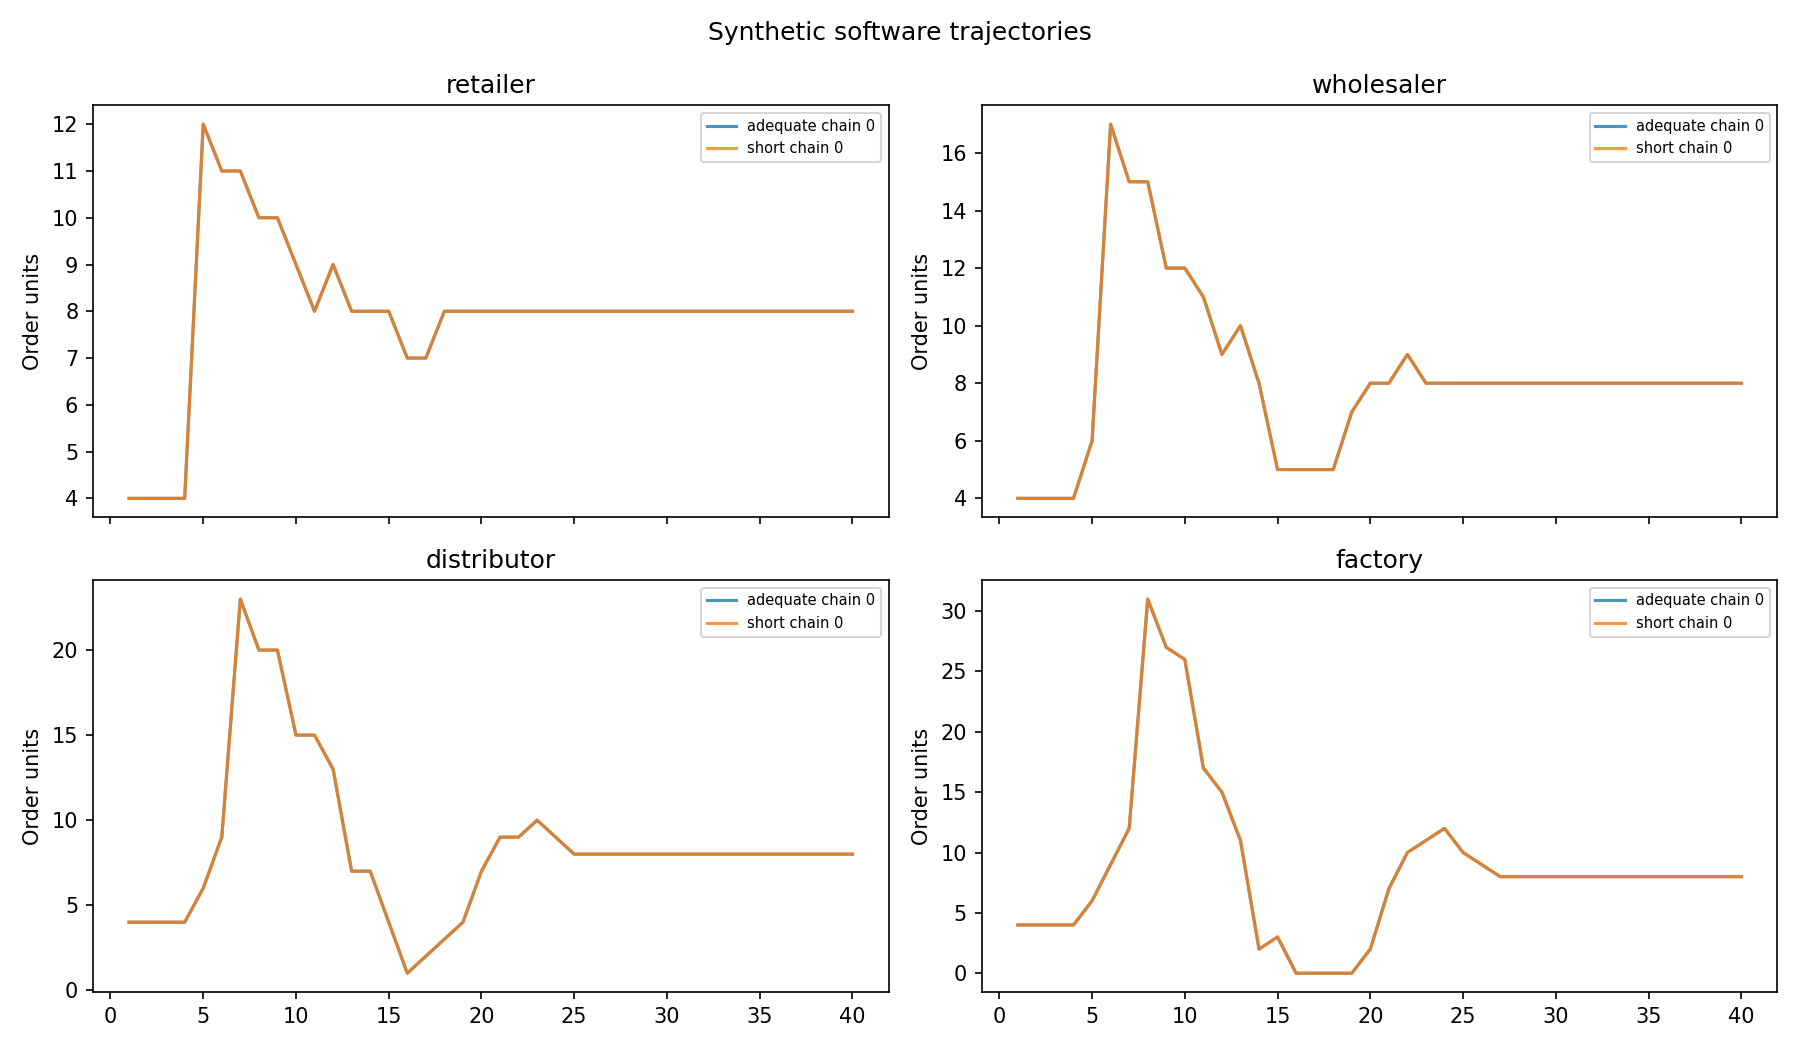

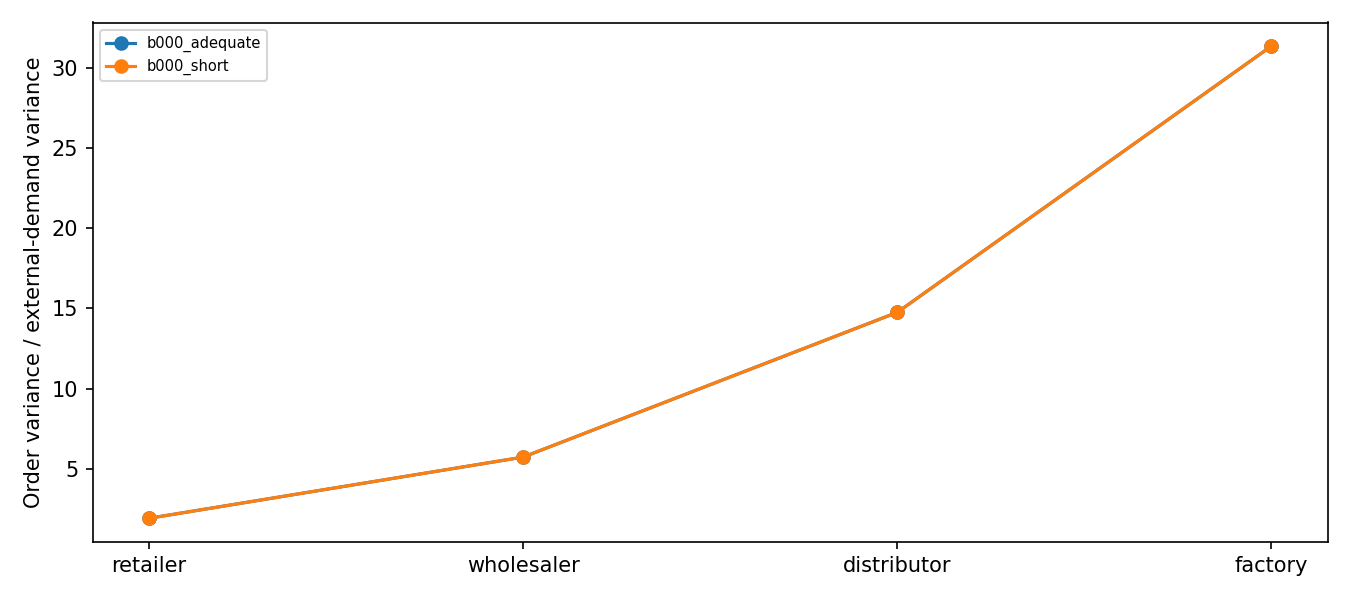

Word report: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/data/runs/game_offline_b2af000ddb619fcc/REPORT.docx
Detailed workbook: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/data/runs/game_offline_b2af000ddb619fcc/DETAILS.xlsx


In [5]:
if (run_dir / "progress.json").exists():
    display(Markdown(report(run_dir)))
    for name in ("order_trajectories.png", "bullwhip.png"):
        if (run_dir / name).exists():
            display(Image(filename=str(run_dir / name)))
    print("Word report:", run_dir / "REPORT.docx")
    print("Detailed workbook:", run_dir / "DETAILS.xlsx")
    if (run_dir / "calibration_recommendation.json").exists():
        import json
        recommendation = json.loads((run_dir / "calibration_recommendation.json").read_text())
        print("Suggested settings (review before using):", recommendation)
        print("CALIBRATION_RUN =", repr(str(run_dir)))
else:
    print("No saved stage yet.")

## 6. What to do next

1. Run this entire notebook in **offline calibration** mode once.
2. Run **API calibration**; review whether the cap binds and the generous/doubled decisions are reasonably stable. A failed screen means the token contrast is not yet established; do not call it a successful time-pressure manipulation.
3. For a passed screen, copy its two budgets and folder into the settings, change `STAGE="game"`, and run **one group per condition** first. Keep `REPLICATE_ID` fixed to resume.
4. Assess beta identification, total costs, actual token use, failure rates and bullwhip patterns. Plan group-level replication/power before the proposed **10 groups per condition**. The previous $3 budget is not assumed sufficient for 80 agents.

No prompt, token budget or model guarantees realistic human behavior, bullwhip amplification or significant H1/H2. The study tests those outcomes.

The updated reflection also proposes explanations/questionnaires. Set `COLLECT_DEBRIEFS=True` **before a new game run** to save one concise retrospective self-report per agent. This is optional, adds API cost, and is separate from decision data. Model self-reports do not establish the actual mechanism behind decisions.